## 1. Setup
### 1.1 Import libraries


In [10]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, silhouette_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler


### 1.2 Locate the dataset


In [11]:
csv_file = Path('CC GENERAL.csv')
if not csv_file.exists():
    raise FileNotFoundError('Put CC GENERAL.csv beside this notebook.')
print('Dataset:', csv_file)


Dataset: CC GENERAL.csv


### 1.3 Load and preview the raw data


In [12]:
df = pd.read_csv(csv_file)
print('Rows and columns:', df.shape)
display(df.head())


Rows and columns: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


## 2. Understand data quality
### 2.1 Inspect columns and types


In [13]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   str    
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHASES_TRX    

### 2.2 Check missing values


In [14]:
display(df.isna().sum()[df.isna().sum() > 0])


CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64

### 2.3 Check duplicates


In [15]:
print('Duplicate rows:', df.duplicated().sum())


Duplicate rows: 0


### 2.4 Review numerical statistics


In [16]:
display(df.describe().round(2))


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8949.00,8950.00,8637.00,8950.00,8950.00
mean,1564.47,0.88,1003.20,592.44,411.07,978.87,0.49,0.20,0.36,0.14,3.25,14.71,4494.45,1733.14,864.21,0.15,11.52
std,2081.53,0.24,2136.63,1659.89,904.34,2097.16,0.40,0.30,0.40,0.20,6.82,24.86,3638.82,2895.06,2372.45,0.29,1.34
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,50.00,0.00,0.02,0.00,6.00
25%,128.28,0.89,39.64,0.00,0.00,0.00,0.08,0.00,0.00,0.00,0.00,1.00,1600.00,383.28,169.12,0.00,12.00
50%,873.39,1.00,361.28,38.00,89.00,0.00,0.50,0.08,0.17,0.00,0.00,7.00,3000.00,856.90,312.34,0.00,12.00
75%,2054.14,1.00,1110.13,577.40,468.64,1113.82,0.92,0.30,0.75,0.22,4.00,17.00,6500.00,1901.13,825.49,0.14,12.00
max,19043.14,1.00,49039.57,40761.25,22500.00,47137.21,1.00,1.00,1.00,1.50,123.00,358.00,30000.00,50721.48,76406.21,1.00,12.00


## 3. Clean the data
### 3.1 Remove duplicate rows


In [17]:
df = df.drop_duplicates().copy()


### 3.2 Review missing values after cleaning

Missing feature values are imputed with the median inside the training-fitted preprocessing pipeline.


In [18]:
display(df.isna().sum()[df.isna().sum() > 0])


CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64

## 4. Exploratory Data Analysis (EDA)
### 4.1 Plot selected numerical features


In [20]:
object_data = df.select_dtypes(include="number")

print("number columns:")
print(object_data.columns.tolist())

object_data.head()

number columns:
['BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


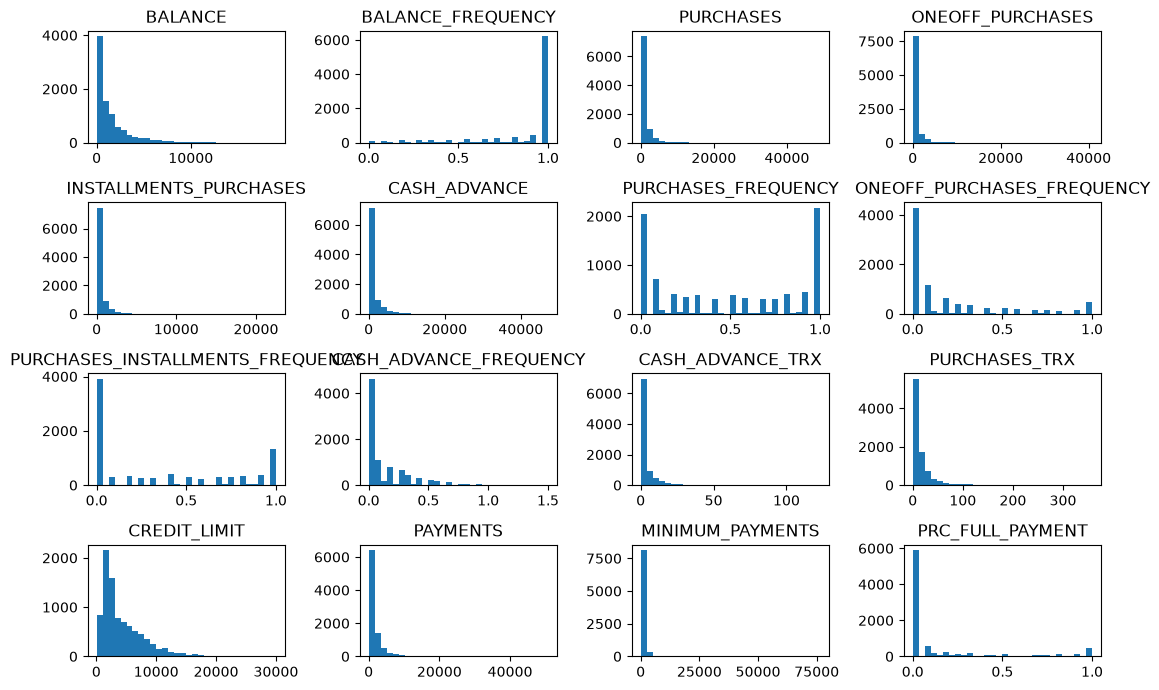

In [24]:
eda_cols =['BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']
fig, axes = plt.subplots(4, 4, figsize=(11, 7))
for ax, col in zip(axes.flat, eda_cols):
    ax.hist(df[col].dropna(), bins=30)
    ax.set_title(col)
plt.tight_layout()
plt.show()


## 5. Select features and split the data
### 5.1 Define feature columns

`CUST_ID` identifies customers and is excluded from model features. All remaining columns are numeric.


In [25]:
feature_cols = [col for col in df.columns if col != 'CUST_ID']


### 5.2 Create the feature table


In [26]:
X = df[feature_cols].copy()


### 5.3 Create train/test sets


In [27]:
X_train, X_test = train_test_split(X, test_size=0.20, random_state=42)
print('Train:', X_train.shape, '| Test:', X_test.shape)


Train: (7160, 17) | Test: (1790, 17)


## 6. Preprocess the features
### 6.1 Prepare numerical features

Fit imputation and scaling on the training split only.


In [28]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, feature_cols)
])
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)
print('Train:', X_train_prepared.shape, '| Test:', X_test_prepared.shape)


Train: (7160, 17) | Test: (1790, 17)


## 7. PCA dimensionality reduction
### 7.1 Learn PCA from training data and transform the test data


In [29]:
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_prepared)
X_test_pca = pca.transform(X_test_prepared)
print('Before PCA:', X_train_prepared.shape[1])
print('After PCA:', X_train_pca.shape[1])
print('Variance retained:', round(pca.explained_variance_ratio_.sum(), 3))


Before PCA: 17
After PCA: 9
Variance retained: 0.953


## 8. Find a suitable number of clusters
### 8.1 Try several K values using training data


In [30]:
k_results = []
for k in range(2, 9):
    candidate = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = candidate.fit_predict(X_train_pca)
    k_results.append({
        'K': k,
        'Inertia': candidate.inertia_,
        'Silhouette': silhouette_score(X_train_pca, labels)
    })
k_scores = pd.DataFrame(k_results)
display(k_scores.round(3))


,K,Inertia,Silhouette
0,2,326112.814,0.689
1,3,272009.287,0.581
2,4,237646.472,0.328
3,5,206256.459,0.338
4,6,183727.523,0.294
5,7,165272.094,0.299
6,8,146783.493,0.305


### 8.2 Plot the elbow curve


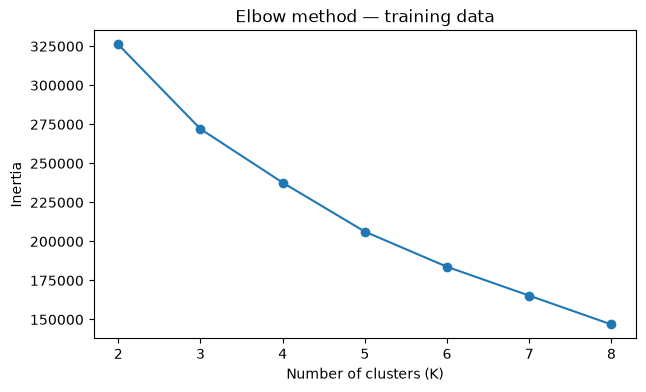

In [31]:
plt.figure(figsize=(7, 4))
plt.plot(k_scores['K'], k_scores['Inertia'], marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow method — training data')
plt.show()


### 8.3 Plot silhouette scores


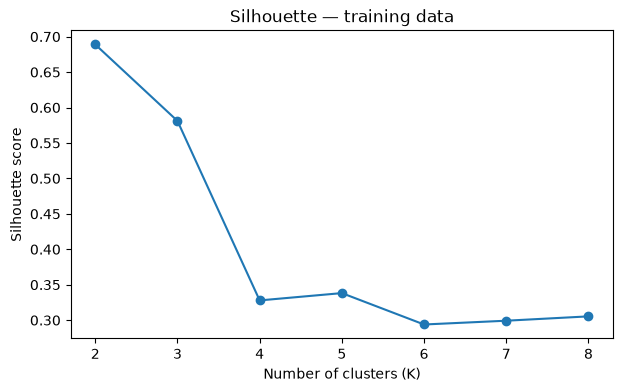

In [32]:
plt.figure(figsize=(7, 4))
plt.plot(k_scores['K'], k_scores['Silhouette'], marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Silhouette score')
plt.title('Silhouette — training data')
plt.show()


### 8.4 Select K using training scores


In [33]:
best_k = int(k_scores.loc[k_scores['Silhouette'].idxmax(), 'K'])
print('Selected number of clusters:', best_k)


Selected number of clusters: 2


## 9. Train and evaluate KMeans
### 9.1 Fit final clustering model and label the test split


In [34]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
kmeans.fit(X_train_pca)
train_clusters = kmeans.labels_
test_clusters = kmeans.predict(X_test_pca)
print('Training silhouette:', round(silhouette_score(X_train_pca, train_clusters), 3))
print('Test silhouette:', round(silhouette_score(X_test_pca, test_clusters), 3))
display(pd.Series(train_clusters, name='Cluster').value_counts().sort_index())


Training silhouette: 0.689
Test silhouette: 0.681


Cluster
0    6892
1     268
Name: count, dtype: int64

## 10. Interpret the customer segments
### 10.1 Combine labels and create cluster profiles


In [35]:
cluster_labels = pd.concat([
    pd.Series(train_clusters, index=X_train.index),
    pd.Series(test_clusters, index=X_test.index)
]).sort_index()
df['Cluster'] = cluster_labels.astype(int)
cluster_profile = df.groupby('Cluster')[feature_cols].mean().round(2)
cluster_profile.insert(0, 'Customers', df['Cluster'].value_counts().sort_index())
display(cluster_profile)


,Customers,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
Cluster,,,,,,,,,,,,,,,,,,
0,8610,1455.24,0.87,739.11,409.4,330.03,957.74,0.48,0.19,0.35,0.14,3.21,12.19,4309.74,1484.73,657.45,0.15,11.50
1,340,4330.64,0.99,7690.91,5227.6,2463.31,1513.98,0.84,0.60,0.68,0.12,4.23,78.60,9171.47,8023.80,5925.11,0.23,11.92


### 10.2 Visualize training customers in two PCA dimensions


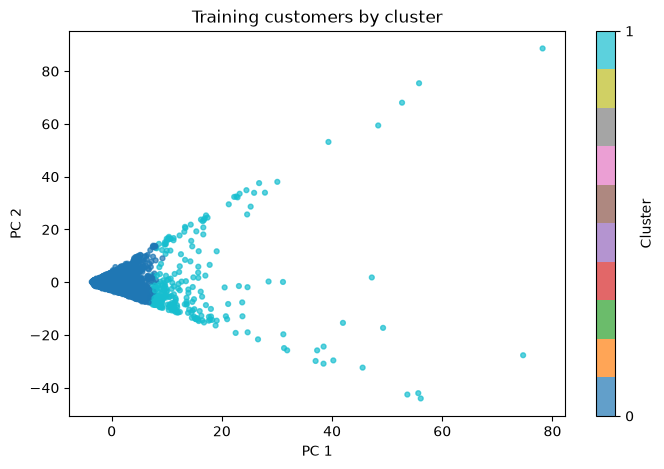

In [36]:
plt.figure(figsize=(8, 5))
points = plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=train_clusters, cmap='tab10', s=12, alpha=0.7)
plt.colorbar(points, label='Cluster', ticks=range(best_k))
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.title('Training customers by cluster')
plt.show()


## 11. Train a classifier to reproduce the clusters
### 11.1 Build the classifier pipeline and parameter search


In [37]:
classifier_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(random_state=42))
])
param_grid = {
    'model__n_estimators': [50, 100],
    'model__max_depth': [None, 10]
}
grid_search = GridSearchCV(classifier_pipeline, param_grid, cv=3, scoring='accuracy')
grid_search.fit(X_train, train_clusters)
print('Best CV accuracy:', round(grid_search.best_score_, 3))
print('Best parameters:', grid_search.best_params_)
best_classifier = grid_search.best_estimator_


Best CV accuracy: 0.995
Best parameters: {'model__max_depth': 10, 'model__n_estimators': 100}


## 12. Test the classifier
### 12.1 Predict held-out customer clusters and calculate accuracy

This score measures agreement with KMeans pseudo-labels, not accuracy against a real customer outcome.


In [38]:
predicted_clusters = best_classifier.predict(X_test)
print('Test accuracy:', round(accuracy_score(test_clusters, predicted_clusters), 3))


Test accuracy: 0.995


## 13. Save and reuse the classifier pipeline
### 13.1 Save, reload, and try the fitted classifier


In [39]:
joblib.dump(best_classifier, 'customer_cluster_classifier.joblib')
loaded_classifier = joblib.load('customer_cluster_classifier.joblib')
print('Predicted clusters:', loaded_classifier.predict(X_test.head()))


Predicted clusters: [0 0 0 0 0]


### 13.2 Export cluster profiles


In [40]:
cluster_profile.to_csv('customer_cluster_profiles.csv')
